In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest

Data ingestion is complete; now it’s time to discover. To help the Ministry of Agriculture uncover the hidden structure of Maji Ndogo's farmlands, you will shift from predicting known labels to exploring raw, unsupervised data. In this project, you will build the foundational toolkit for unsupervised machine learning using scikit-learn to compress and map 5,654 fields across 8 environmental features. You will implement **Principal Component Analysis (PCA)** to combat the Curse of Dimensionality, leverage **t-SNE** to project complex interactions into a visual 2D map, and deploy an **Isolation Forest** to isolate the top 5% most anomalous fields for targeted quality control. This is the critical exploratory baseline that anchors an unsupervised learning portfolio and sets the stage for advanced clustering.

In [7]:
import os

# Database file
db_file = 'Maji_Ndogo_farm_survey_small.db'

# Check if database exists
if not os.path.exists(db_file):
    raise FileNotFoundError(
        f"Database file '{db_file}' not found. "
        "Please place Maji_Ndogo_farm_survey_small.db "
        "in the same folder as this notebook."
    )

# Create SQLAlchemy engine
engine = create_engine(f'sqlite:///{db_file}')

# SQL query
sql_query = """
SELECT
    Elevation,
    Rainfall,
    Ave_temps,
    Soil_fertility,
    pH,
    Pollution_level,
    Plot_size,
    Standard_yield
FROM geographic_features
LEFT JOIN weather_features USING (Field_ID)
LEFT JOIN soil_and_crop_features USING (Field_ID)
LEFT JOIN farm_management_features USING (Field_ID)
"""

# Execute query and load data
with engine.connect() as conn:
    df = pd.read_sql_query(sql_query, conn)

# Remove missing values
df = df.dropna()

# Display results
print(f'Dataset shape: {df.shape}')
display(df.head())

# Dispose of the engine
engine.dispose()

Dataset shape: (5654, 8)


,Elevation,Rainfall,Ave_temps,Soil_fertility,pH,Pollution_level,Plot_size,Standard_yield
0,786.05580,1125.2,15.00,0.62,6.169393,0.085267,1.3,0.577964
1,674.33410,1450.7,13.35,0.64,5.676648,0.399684,2.2,0.486302
2,826.53390,2208.9,13.30,0.69,5.331993,0.358029,3.4,0.649647
3,574.94617,328.8,13.20,0.54,5.328150,0.286687,2.4,0.532348
4,886.35300,785.2,14.25,0.72,5.721234,0.043190,1.5,0.555076


 ---
#### **Challenge 1: The Essence of the Environment (PCA)**

Our 8-feature dataset lives in an 8-dimensional space. PCA finds the directions — called **principal components** — along which the data varies the most, then projects everything down into those directions. The result is a lower-dimensional representation that preserves as much information as possible.

The key question we need to answer for Sanaa is: **how many components do we actually need?** We track this using the **cumulative explained variance ratio** — the proportion of total variance accounted for as we add more components.

If 6 components capture 85% of the variance, we can discard 2 dimensions and lose only 15% of the information. That is the trade-off PCA makes transparent.

#### **Task**
Create a function `apply_pca` that scales the data, applies PCA with the specified number of components, and returns the cumulative explained variance ratio as a NumPy array.

**Function specifications:**
- Takes a DataFrame `df` and an integer `n_components` as input.
- Scales the data using `StandardScaler` (fit and transform on the full DataFrame).
- Applies `PCA` with `n_components` components.
- Returns the **cumulative** explained variance ratio as a NumPy array (use `np.cumsum`).

> **Note:** PCA is sensitive to feature scale. Always scale first.

In [8]:
def apply_pca(df, n_components):

    # Standardise the features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df)

    # Apply PCA
    pca = PCA(n_components=n_components)
    pca.fit(X_scaled)

    # Calculate cumulative explained variance
    cum_var = np.cumsum(
        pca.explained_variance_ratio_
    )

    return cum_var

In [9]:
# Apply PCA with 8 components
cumulative_variance = apply_pca(df, 8)

print("Cumulative explained variance (8 components):")
print(np.round(cumulative_variance, 4))

Cumulative explained variance (8 components):
[0.2514 0.4455 0.6005 0.7385 0.8372 0.9117 0.9821 1.    ]


In [ ]:
# Apply PCA with 8 components
cumulative_variance = apply_pca(df, 2)

print("Cumulative explained variance (2 components):")He
print(np.round(cumulative_variance, 4))

Cumulative explained variance (2 components):
[0.2514 0.4455]


---

#### **Challenge 2: Visualizing the Hidden Structure (t-SNE)**

PCA is a linear technique — it projects data along straight-line directions. But agricultural patterns in the real world are rarely linear. Soil type, micro-climate, and elevation interact in complex, curved ways.

**t-SNE (t-Distributed Stochastic Neighbor Embedding)** is a non-linear technique designed specifically for visualization. It places data points in 2D space such that points that are similar in the original high-dimensional space end up close together. It is exceptionally good at revealing clusters and groupings that PCA would smooth over.

We will use it to generate a 2D map of Maji Ndogo's 5,654 fields. If natural agricultural zones exist in this data, t-SNE will reveal them visually — even though we have never told the algorithm anything about crop types or provinces.

#### **Task**
Create a function `run_tsne` that reduces the dataset to 2 dimensions using t-SNE and returns the coordinates as a NumPy array.

**Function specifications:**
- Takes a DataFrame `df` as input.
- Scales the data using `StandardScaler`.
- Applies `TSNE` with `n_components=2` and `random_state=42`.
- Returns the resulting 2D array (shape: `(n_fields, 2)`, dtype: `float32`).

> **Note:** t-SNE is stochastic but fixing `random_state` makes results reproducible. On 5,654 rows it will take 30–60 seconds to run — this is normal.


In [10]:
def run_tsne(df):
    # Scale the data
    # Run t-SNE with 2 components and random_state=42

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df)

    tsne = TSNE(n_components=2, random_state=42)
    X_tsne = tsne.fit_transform(X_scaled)

    return X_tsne

In [11]:
# Run t-SNE
tsne_results = run_tsne(df)

# Display output shape and data type
print("t-SNE output shape:", tsne_results.shape)
print("dtype:", tsne_results.dtype)

t-SNE output shape: (5654, 2)
dtype: float32


In [13]:
import matplotlib.pyplot as plt

def style_plot(
    ax,
    title=None,
    xlabel=None,
    ylabel=None,
    title_fontsize=14,
    label_fontsize=11,
    remove_spines=True,
    grid=True,
    legend=True,
    xlim=None,
    ylim=None,
):
    """Apply a consistent style to a matplotlib Axes object."""
    if title:
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold",
            pad=15)

    if xlabel:
        ax.set_xlabel(xlabel, fontsize=label_fontsize)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=label_fontsize)
    if grid:
        ax.grid(True, linestyle="--", alpha=0.4, linewidth=0.3, color="gray")
    if legend:
        ax.legend(fontsize=9)

    if remove_spines:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        for spine in ax.spines.values():
            spine.set_linewidth(1.2)

    ax.set_facecolor("whitesmoke")

    if xlim:
        ax.set_xlim(xlim)
    if ylim:
        ax.set_ylim(ylim)

    return ax


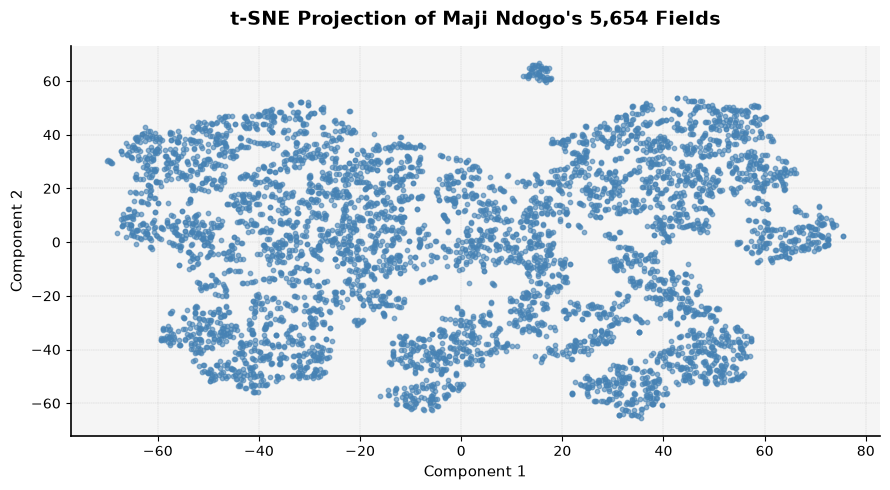

In [26]:
# Visualize t-SNE results using style_plot function
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    tsne_results[:, 0], 
    tsne_results[:, 1], 
    s = 10,
    c="steelblue", 
   alpha = 0.6
)


style_plot(
    ax, 
    title="t-SNE Projection of Maji Ndogo's 5,654 Fields", 
    xlabel="Component 1", 
    ylabel="Component 2",
    legend =False
)

plt.tight_layout()
plt.show()

#### **Interpretation of the t-SNE Projection**

The t-SNE visualization reveals a complex, non-linear distribution of Maji Ndogo's 5,654 agricultural fields across the two-dimensional space.

__Observations:__

- **Non-linear structure:** The observations form several sprawling and interconnected patterns, suggesting that relationships among the eight features may be more complex than simple linear relationships.
- **Multiple groupings:** Several dense clusters and smaller, distinct groupings are visible, indicating that some fields share similar combinations of agricultural and environmental characteristics.
- **Distinct upper cluster:** A compact island appears around Component 1 = 15 and Component 2 = 60. This group may represent fields with feature profiles that differ from those of the surrounding observations.
- **Overall variation:** The broad distribution of points highlights the diversity of conditions across the agricultural fields.

#### **Conclusion**

The t-SNE projection reveals meaningful patterns and potential groupings within the Maji Ndogo dataset. These patterns provide an opportunity to investigate similarities among agricultural fields and identify observations that may warrant further analysis.

__Technical note:__ t-SNE primarily preserves local neighbourhood relationships. Its components have no direct physical interpretation, and visual separation alone does not establish distinct agricultural categories. Further investigation using the original features is needed to understand the characteristics of the observed clusters.

---
#### **Challenge 3: Finding the Outliers (Isolation Forest)**

Not every field in Maji Ndogo behaves like its neighbors. Some fields have unusual combinations of features — a very high pH paired with very low rainfall, or an anomalous pollution reading inconsistent with any nearby station. These could be:

- **Sensor errors:** A malfunctioning weather station or soil probe.
- **Data entry mistakes:** A field ID linked to the wrong set of measurements.
- **Genuine micro-climates:** Rare agricultural environments that may deserve special attention.

**Isolation Forest** finds these outliers by randomly partitioning the data into trees. Outliers are the points that get isolated quickly — they require fewer splits to separate from the rest because they sit far from the main body of data.

We set `contamination=0.05`, which tells the model to flag the most anomalous 5% of fields — approximately 283 out of 5,654.

#### **Task**
Create a function `detect_anomalies` that fits an Isolation Forest and returns the indices of anomalous fields.

**Function specifications:**
- Takes a DataFrame `df` as input (unscaled — the Isolation Forest handles this internally).
- Initializes `IsolationForest` with `contamination=0.05` and `random_state=42`.
- Fits and predicts on the full DataFrame. Isolation Forest labels inliers as `1` and outliers as `-1`.
- Returns a **list** of DataFrame indices where the prediction is `-1`.

> **Note:** Return `df.index[preds == -1].tolist()` — these are the *row labels* (DataFrame index), not positional integers.



In [20]:
def detect_anomalies(df, contamination=0.05):
    # Initialize IsolationForest with contamination=0.05 and random_state=42
    # Fit and predict
    # Return a list of indices where prediction == -1

    iso_forest = IsolationForest(contamination=contamination, random_state=42)
    preds = iso_forest.fit_predict(df)
    anomaly_indices = df.index[preds == -1].tolist()
    return anomaly_indices

In [21]:
anomaly_indices = detect_anomalies(df)
print(f'Anomalies detected: {len(anomaly_indices)}')
print(f'First five anomalous field indices: {anomaly_indices[:5]}')

Anomalies detected: 283
First five anomalous field indices: [15, 54, 78, 86, 99]


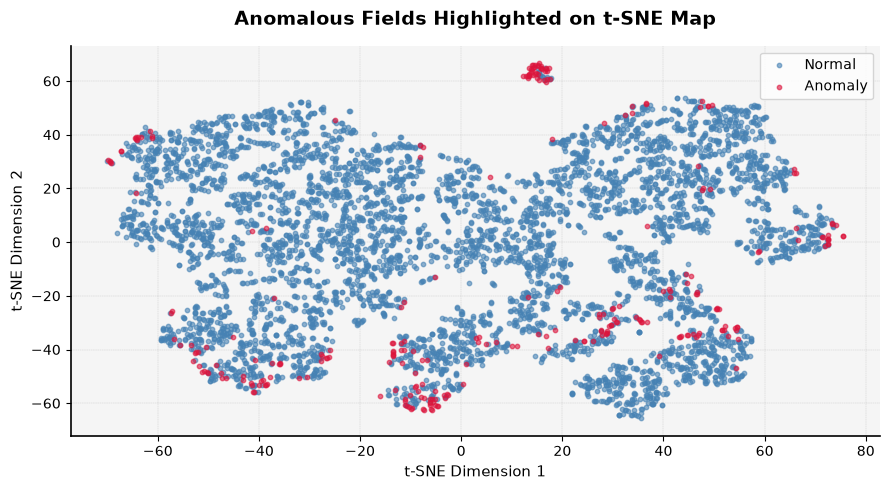

In [27]:
# Identify anomalous observations
is_anomaly = np.isin(df.index, anomaly_indices)

# Create figure and axes
fig, ax = plt.subplots(figsize=(9, 5))

# Plot normal observations
ax.scatter(
    tsne_results[~is_anomaly, 0],
    tsne_results[~is_anomaly, 1],
    s=10,
    alpha=0.6,
    c="steelblue",
    label="Normal"
)

# Plot anomalous observations
ax.scatter(
    tsne_results[is_anomaly, 0],
    tsne_results[is_anomaly, 1],
    s=10,
    alpha=0.6,
    c="crimson",
    label="Anomaly"
)

# Apply consistent styling
style_plot(
    ax,
    title="Anomalous Fields Highlighted on t-SNE Map",
    xlabel="t-SNE Dimension 1",
    ylabel="t-SNE Dimension 2"
)

ax.legend()
plt.tight_layout()
plt.show()

#### **Interpretation of Anomalies on the t-SNE Map**

The visualization shows that the anomalous fields identified by the Isolation Forest are distributed across different regions of the t-SNE map rather than being concentrated in a single location.

__Several observations stand out:__

- **Concentration at the lower boundary:** A noticeable number of anomalies appear between approximately Y = -60 and Y = -40. This suggests that some fields have feature combinations that distinguish them from much of the normal data.
- **Distinct upper cluster:** Another compact concentration appears near X = 15 and Y = 60, indicating a group of fields with potentially similar unusual characteristics.
- **Anomalies around cluster boundaries:** Several red points occur along the outer edges of the larger blue clusters, suggesting observations that differ from the dominant feature patterns.
- **Variation in anomalous patterns:** The presence of anomalies in multiple regions suggests that unusual agricultural conditions are not necessarily associated with one common feature combination.

#### __Conclusion__

The t-SNE visualization provides a useful view of how the Isolation Forest anomalies are distributed relative to the broader dataset. The concentration of anomalous observations in certain regions suggests that some fields may have distinctive combinations of environmental and agricultural characteristics. These observations could represent sensor errors, data-entry issues, or genuine environmental variations requiring further investigation.

__Important qualification:__
 t-SNE preserves local neighbourhood structure imperfectly, and distances between separate clusters should not be interpreted as exact measures of dissimilarity. Furthermore, the map does not establish why a field was flagged. Further investigation of the original feature values is necessary to determine whether the anomalies represent data-quality problems or genuine agricultural conditions.